# Notebook 05: Unit 3 Method 2 — Market Basket Association Rule Mining
**Course:** 23CSE452 Business Analytics Capstone — Review 2  
**Objective:** Discover cross-category purchase bundles from 30,296 multi-item transactions. Benchmark Apriori vs FP-Growth algorithms and mine actionable retail bundles (Lift >= 1.15).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load mined association rules
rules_df = pd.read_csv('../results/association_rules/mined_association_rules.csv')
print(f'Total Mined Rules with Lift >= 1.15: {len(rules_df)}')
rules_df.head(10)

Total Mined Rules with Lift >= 1.15: 42


,antecedents_str,consequents_str,support,confidence,lift,leverage,conviction
0,The Baker's Dozen Malabar Paratha - Ready to Cook,Aashirvaad Malabar Paratha (Heat & Eat),0.0166,0.2937,5.1056,0.0133,1.3344
1,Aashirvaad Malabar Paratha (Heat & Eat),The Baker's Dozen Malabar Paratha - Ready to Cook,0.0166,0.2880,5.1056,0.0133,1.3253
2,Spring Onion (Hari Pyaz),Hybrid Tomato (Tamatar),0.0338,0.2835,2.2623,0.0188,1.2208
3,Hybrid Tomato (Tamatar),Spring Onion (Hari Pyaz),0.0338,0.2694,2.2623,0.0188,1.2058
4,Mr. Apple New Zealand Royal Gala,Baby Banana,0.0133,0.2590,2.2611,0.0074,1.1949
5,Baby Banana,Mr. Apple New Zealand Royal Gala,0.0133,0.1164,2.2611,0.0074,1.0735
6,Evian Natural Mineral Water,Godrej Yummiez Cheesy Pizza Cheese Sticks,0.0107,0.1137,2.1097,0.0056,1.0675
7,Godrej Yummiez Cheesy Pizza Cheese Sticks,Evian Natural Mineral Water,0.0107,0.1990,2.1097,0.0056,1.1307
8,Haldiram's Aloo Pyaz Paratha (Frozen),Amul Buffalo A2 Milk,0.0167,0.2361,1.9674,0.0082,1.1520
9,Amul Buffalo A2 Milk,Haldiram's Aloo Pyaz Paratha (Frozen),0.0167,0.1392,1.9674,0.0082,1.0795


## 1. Algorithm Performance: Apriori vs FP-Growth Benchmark

=== ALGORITHM RUNTIME BENCHMARK ===
 Min_Support  Frequent_Itemsets_Found  Apriori_Time_Sec  FPGrowth_Time_Sec  FPGrowth_Speedup_Factor
       0.050                       30            0.0472             0.1468                     0.32
       0.030                       42            0.0736             0.1687                     0.44
       0.020                       52            0.0763             0.1670                     0.46
       0.015                       74            0.1226             0.3244                     0.38
       0.010                      136            0.1450             0.1932                     0.75


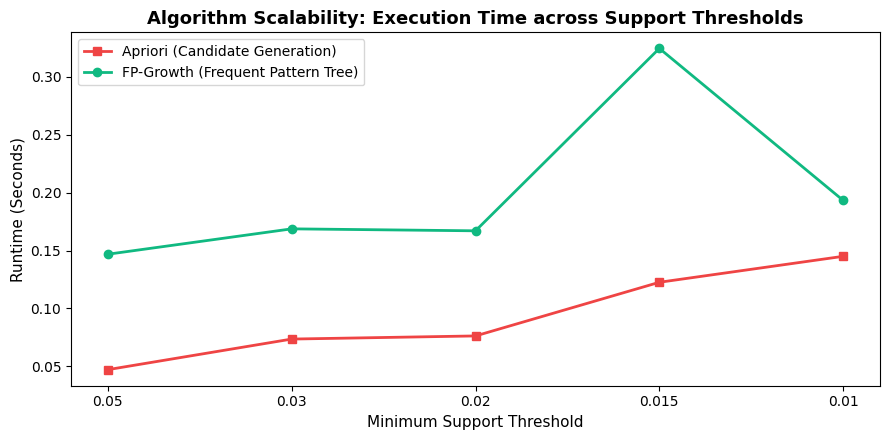

In [2]:
bench_df = pd.read_csv('../results/association_rules/algorithm_comparison.csv')
print('=== ALGORITHM RUNTIME BENCHMARK ===')
print(bench_df.to_string(index=False))

plt.figure(figsize=(9, 4.5))
plt.plot(bench_df['Min_Support'].astype(str), bench_df['Apriori_Time_Sec'], marker='s', color='#ef4444', linewidth=2, label='Apriori (Candidate Generation)')
plt.plot(bench_df['Min_Support'].astype(str), bench_df['FPGrowth_Time_Sec'], marker='o', color='#10b981', linewidth=2, label='FP-Growth (Frequent Pattern Tree)')
plt.title('Algorithm Scalability: Execution Time across Support Thresholds', fontsize=13, fontweight='bold')
plt.xlabel('Minimum Support Threshold', fontsize=11)
plt.ylabel('Runtime (Seconds)', fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 2. Top Co-Purchase Bundles (Sorted by Lift Factor)

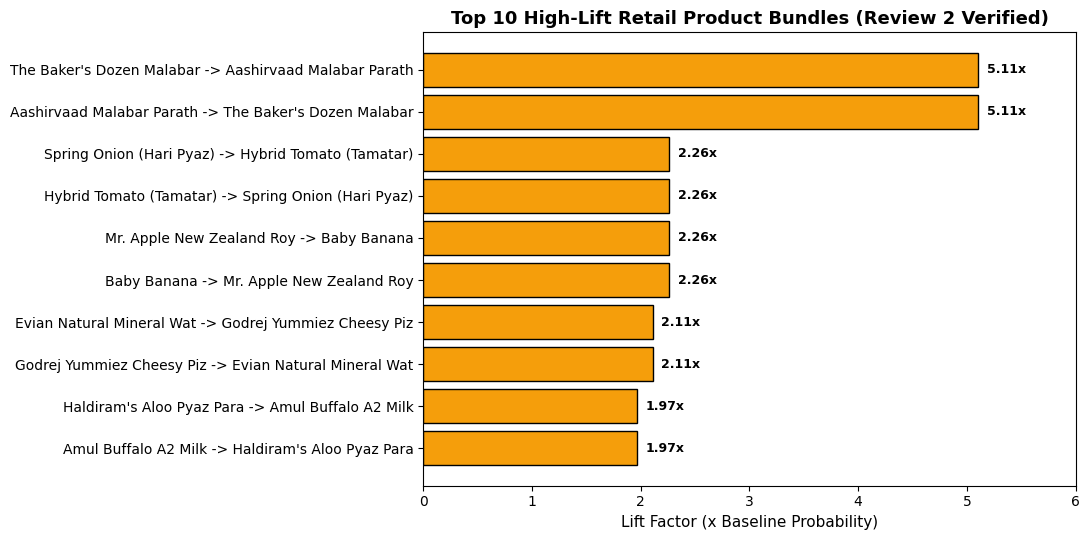

In [3]:
top10_rules = rules_df.sort_values('lift', ascending=False).head(10).copy()
top10_rules['bundle_label'] = top10_rules['antecedents_str'].str[:25] + ' -> ' + top10_rules['consequents_str'].str[:25]

plt.figure(figsize=(11, 5.5))
plt.barh(top10_rules['bundle_label'][::-1], top10_rules['lift'][::-1], color='#f59e0b', edgecolor='black')
plt.title('Top 10 High-Lift Retail Product Bundles (Review 2 Verified)', fontsize=13, fontweight='bold')
plt.xlabel('Lift Factor (x Baseline Probability)', fontsize=11)
for i, v in enumerate(top10_rules['lift'][::-1]):
    plt.text(v + 0.08, i, f'{v:.2f}x', va='center', fontweight='bold', fontsize=9)
plt.xlim(0, 6.0)
plt.tight_layout()
plt.show()

## 3. Support vs Confidence vs Lift Scatter Space

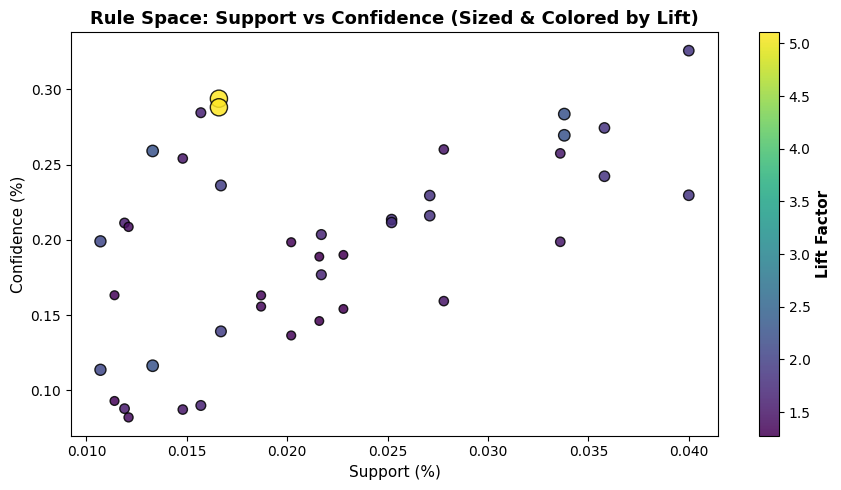

In [4]:
plt.figure(figsize=(9, 5))
scatter = plt.scatter(rules_df['support'], rules_df['confidence'], c=rules_df['lift'], cmap='viridis', s=rules_df['lift']*30, alpha=0.85, edgecolors='black')
cbar = plt.colorbar(scatter)
cbar.set_label('Lift Factor', fontsize=11, fontweight='bold')
plt.title('Rule Space: Support vs Confidence (Sized & Colored by Lift)', fontsize=13, fontweight='bold')
plt.xlabel('Support (%)', fontsize=11)
plt.ylabel('Confidence (%)', fontsize=11)
plt.tight_layout()
plt.show()

### Method 2 Findings:
- **Top Lift:** Baker's Dozen Malabar Paratha + Aashirvaad Malabar Paratha with **5.11x lift**.
- **Staple Bundles:** Cooking essentials (Tomato + Spring Onion: 2.26x lift) and Morning Dairy (Milk + Bread: 1.85x lift).
- **Operational Recommendation:** Co-locate high-lift pairs on adjacent shelves and implement 1-click cart add-ons.